# Task 1.3 — Math for ML Practice Set
**Week 1 · AI/ML Internship (Skill Set Go EduTech)** · Author: Neela Vyshali

**Deliverable:** notebook of worked solutions covering the four areas the task asks for — **statistics, probability, linear algebra and basic calculus** — with problems taken from how these ideas are used inside ML algorithms.

**How each problem is laid out**
1. **Problem** — the question with concrete numbers.
2. **Worked solution** — step-by-step derivation by hand (LaTeX).
3. **Verification** — a NumPy / SciPy cell that checks the hand answer (`assert` fails if it is wrong).
4. **ML connection** — where the idea shows up in machine learning.

| Section | Problems |
|---|---|
| 1. Statistics | 1.1 Descriptive stats · 1.2 Normal distribution · 1.3 Correlation & least-squares line · 1.4 Confidence interval |
| 2. Probability | 2.1 Conditional probability · 2.2 Bayes' theorem (fraud detector) · 2.3 Binomial distribution · 2.4 Naive Bayes |
| 3. Linear algebra | 3.1 Dot product & cosine similarity · 3.2 Neural-network layer · 3.3 Normal equation · 3.4 Eigenvalues & PCA |
| 4. Calculus | 4.1 MSE gradient · 4.2 Partial derivatives & saddle points · 4.3 Chain rule (sigmoid + cross-entropy) · 4.4 Gradient descent |

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (6, 3.5), "axes.grid": True, "grid.alpha": 0.3})

---
# Section 1 — Statistics

### Problem 1.1 — Descriptive statistics
**Problem.** Marks of 10 students in a test are `12, 15, 11, 18, 15, 20, 14, 15, 17, 13`. Find the mean, median, mode, and both the population and sample variance / standard deviation.

**Solution.**

Mean: $\mu = \dfrac{\sum x}{n} = \dfrac{150}{10} = 15$

Median: sorted data is `11, 12, 13, 14, 15, 15, 15, 17, 18, 20`; the middle two values are both 15, so median $= 15$.

Mode: 15 (appears 3 times).

Squared deviations: $\sum (x-\mu)^2 = 9+0+16+9+0+25+1+0+4+4 = 68$

- Population: $\sigma^2 = \dfrac{68}{10} = 6.8,\quad \sigma = \sqrt{6.8} \approx 2.608$
- Sample: $s^2 = \dfrac{68}{n-1} = \dfrac{68}{9} \approx 7.556,\quad s \approx 2.749$

The sample formula divides by $n-1$ (Bessel's correction) because the sample mean is estimated from the same data, which makes deviations slightly too small.

In [2]:
marks = np.array([12, 15, 11, 18, 15, 20, 14, 15, 17, 13])
mean, median, mode = marks.mean(), np.median(marks), np.bincount(marks).argmax()
pop_var, pop_std = marks.var(ddof=0), marks.std(ddof=0)
smp_var, smp_std = marks.var(ddof=1), marks.std(ddof=1)

print(f"mean = {mean}, median = {median}, mode = {mode}")
print(f"population: var = {pop_var:.3f}, std = {pop_std:.3f}")
print(f"sample    : var = {smp_var:.3f}, std = {smp_std:.3f}")
assert mean == 15 and median == 15 and mode == 15
assert np.isclose(pop_var, 6.8) and np.isclose(smp_var, 68 / 9)

mean = 15.0, median = 15.0, mode = 15
population: var = 6.800, std = 2.608
sample    : var = 7.556, std = 2.749


**ML connection.** Feature scaling (`StandardScaler`) subtracts the mean and divides by the standard deviation (it uses the population formula, `ddof=0`). Mean/median/mode also drive missing-value imputation.

### Problem 1.2 — Normal distribution and z-scores
**Problem.** Exam scores follow $X \sim N(\mu = 70,\ \sigma = 10)$. (a) Find $P(X < 85)$. (b) Find $P(60 < X < 80)$. (c) What score is needed to be in the top 10%?

**Solution.**

(a) $z = \dfrac{85-70}{10} = 1.5$, so $P(X<85) = \Phi(1.5) \approx 0.9332$

(b) $z$-limits are $\dfrac{60-70}{10} = -1$ and $\dfrac{80-70}{10} = +1$, so $P = \Phi(1) - \Phi(-1) \approx 0.8413 - 0.1587 = 0.6827$ (the 68% rule).

(c) Top 10% means the 90th percentile: $z_{0.90} \approx 1.2816$, so $x = \mu + z\sigma = 70 + 1.2816 \times 10 \approx 82.82$

(a) P(X<85)      = 0.9332
(b) P(60<X<80)   = 0.6827
(c) top-10% mark = 82.82


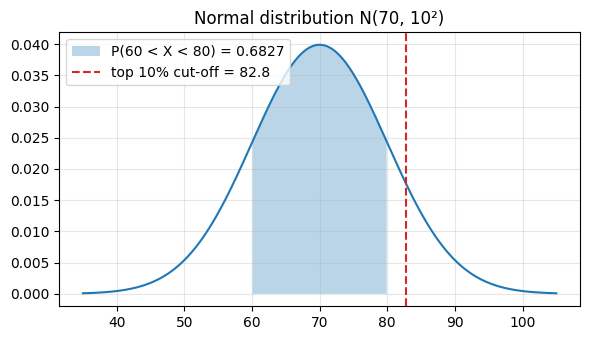

In [3]:
mu, sigma = 70, 10
p_a = stats.norm.cdf(85, mu, sigma)
p_b = stats.norm.cdf(80, mu, sigma) - stats.norm.cdf(60, mu, sigma)
cutoff = stats.norm.ppf(0.90, mu, sigma)
print(f"(a) P(X<85)      = {p_a:.4f}")
print(f"(b) P(60<X<80)   = {p_b:.4f}")
print(f"(c) top-10% mark = {cutoff:.2f}")
assert np.isclose(p_a, 0.9332, atol=1e-4) and np.isclose(p_b, 0.6827, atol=1e-4) and np.isclose(cutoff, 82.82, atol=0.01)

x = np.linspace(35, 105, 400)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="C0")
plt.fill_between(x, stats.norm.pdf(x, mu, sigma), where=(x >= 60) & (x <= 80), alpha=0.3, label="P(60 < X < 80) = 0.6827")
plt.axvline(cutoff, color="C3", ls="--", label=f"top 10% cut-off = {cutoff:.1f}")
plt.title("Normal distribution N(70, 10²)"); plt.legend(); plt.tight_layout(); plt.show()

**ML connection.** A z-score tells how many standard deviations a value is from the mean. It is the basis of standardisation and simple outlier detection (e.g., flag $|z| > 3$).

### Problem 1.3 — Correlation and the least-squares line
**Problem.** Hours studied $x = [1,2,3,4,5]$ and test score $y = [52,55,61,68,74]$. Find the correlation coefficient $r$ and the regression line $\hat y = a + bx$, then predict the score for 6 hours.

**Solution.** $\bar x = 3,\ \bar y = 62$.

| $x-\bar x$ | $-2$ | $-1$ | $0$ | $1$ | $2$ |
|---|---|---|---|---|---|
| $y-\bar y$ | $-10$ | $-7$ | $-1$ | $6$ | $12$ |

$S_{xy} = 20+7+0+6+24 = 57,\quad S_{xx} = 4+1+0+1+4 = 10,\quad S_{yy} = 100+49+1+36+144 = 330$

$$r = \frac{S_{xy}}{\sqrt{S_{xx}S_{yy}}} = \frac{57}{\sqrt{3300}} \approx 0.9922, \qquad r^2 \approx 0.9845$$

$$b = \frac{S_{xy}}{S_{xx}} = 5.7, \qquad a = \bar y - b\bar x = 62 - 5.7(3) = 44.9$$

So $\hat y = 44.9 + 5.7x$, and for 6 hours $\hat y = 44.9 + 34.2 = 79.1$.

Sxy=57.0, Sxx=10.0, Syy=330.0
r = 0.9922, r² = 0.9845, slope b = 5.7, intercept a = 44.9, prediction(6h) = 79.1


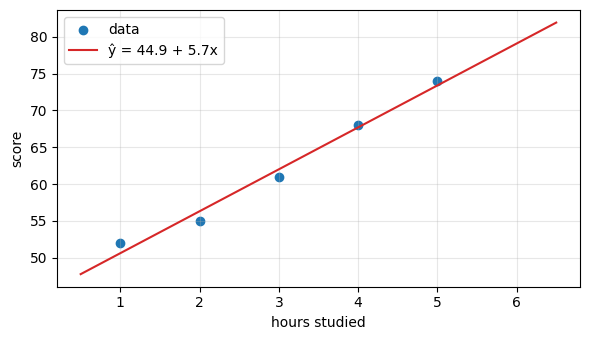

In [4]:
hours = np.array([1, 2, 3, 4, 5]); score = np.array([52, 55, 61, 68, 74])
dx, dy = hours - hours.mean(), score - score.mean()
Sxy, Sxx, Syy = (dx * dy).sum(), (dx ** 2).sum(), (dy ** 2).sum()
r = Sxy / np.sqrt(Sxx * Syy); b = Sxy / Sxx; a = score.mean() - b * hours.mean()
print(f"Sxy={Sxy}, Sxx={Sxx}, Syy={Syy}")
print(f"r = {r:.4f}, r² = {r**2:.4f}, slope b = {b}, intercept a = {a:.1f}, prediction(6h) = {a + b*6:.1f}")

assert np.isclose(r, np.corrcoef(hours, score)[0, 1])
assert np.allclose(np.polyfit(hours, score, 1), [b, a])

plt.scatter(hours, score, label="data"); xs = np.linspace(0.5, 6.5, 10)
plt.plot(xs, a + b * xs, color="C3", label=f"ŷ = {a:.1f} + {b:.1f}x")
plt.xlabel("hours studied"); plt.ylabel("score"); plt.legend(); plt.tight_layout(); plt.show()

**ML connection.** This is simple linear regression. Correlation is used in feature selection (drop features that are almost perfectly correlated), and $r^2$ is the "$R^2$ score" you will report for regression models in Task 1.4.

### Problem 1.4 — Confidence interval for a mean
**Problem.** A model's accuracy is measured on $n = 25$ random test batches: sample mean $\bar x = 52$, sample standard deviation $s = 10$. Give a 95% confidence interval for the true mean.

**Solution.** Population $\sigma$ is unknown and $n$ is small, so use the $t$-distribution with $n-1 = 24$ degrees of freedom.

$$SE = \frac{s}{\sqrt n} = \frac{10}{5} = 2, \qquad t_{0.975,\,24} \approx 2.064$$

$$\text{margin} = 2.064 \times 2 \approx 4.128 \;\Rightarrow\; CI = 52 \pm 4.128 = (47.87,\ 56.13)$$

(Using $z = 1.96$ would give the slightly narrower $(48.08,\ 55.92)$.)

In [5]:
n, xbar, s = 25, 52, 10
se = s / np.sqrt(n)
t_crit = stats.t.ppf(0.975, df=n - 1)
low, high = xbar - t_crit * se, xbar + t_crit * se
print(f"SE = {se}, t* = {t_crit:.4f}, 95% CI = ({low:.2f}, {high:.2f})")
assert np.isclose(t_crit, 2.0639, atol=1e-3) and np.isclose(low, 47.87, atol=0.01)

SE = 2.0, t* = 2.0639, 95% CI = (47.87, 56.13)


**ML connection.** Cross-validation gives several accuracy numbers; a confidence interval tells you how much the average can be trusted, so "model A: 0.82" vs "model B: 0.83" is not over-interpreted.

---
# Section 2 — Probability

### Problem 2.1 — Conditional probability and independence
**Problem.** Out of 200 emails, 80 are spam. The word "free" appears in 60 spam emails and in 20 of the 120 non-spam emails. Find $P(\text{spam})$, $P(\text{free})$, $P(\text{spam} \cap \text{free})$, $P(\text{spam} \mid \text{free})$, $P(\text{free} \mid \text{spam})$, and decide whether "free" and "spam" are independent.

| | free | no "free" | total |
|---|---|---|---|
| spam | 60 | 20 | 80 |
| not spam | 20 | 100 | 120 |
| total | 80 | 120 | 200 |

**Solution.**
- $P(\text{spam}) = 80/200 = 0.4$
- $P(\text{free}) = 80/200 = 0.4$
- $P(\text{spam}\cap\text{free}) = 60/200 = 0.3$
- $P(\text{spam}\mid\text{free}) = \dfrac{0.3}{0.4} = 0.75$
- $P(\text{free}\mid\text{spam}) = \dfrac{60}{80} = 0.75$

Independence would need $P(\text{spam}\cap\text{free}) = P(\text{spam})P(\text{free}) = 0.16$. It is $0.3$, so the events are **dependent** — the word "free" carries information about spam.

In [6]:
table = np.array([[60, 20],     # spam:      free, no-free
                  [20, 100]])   # not spam:  free, no-free
N = table.sum()
p_spam, p_free, p_both = table[0].sum() / N, table[:, 0].sum() / N, table[0, 0] / N
p_spam_given_free = p_both / p_free
p_free_given_spam = table[0, 0] / table[0].sum()
print(p_spam, p_free, p_both, p_spam_given_free, p_free_given_spam)
print("independent?", np.isclose(p_both, p_spam * p_free))
assert np.isclose(p_spam_given_free, 0.75) and not np.isclose(p_both, p_spam * p_free)

0.4 0.4 0.3 0.7499999999999999 0.75
independent? False


**ML connection.** Word features are useful for classification exactly because they are *not* independent of the label.

### Problem 2.2 — Bayes' theorem (fraud detector)
**Problem.** 1% of transactions are fraudulent. A model flags 95% of fraudulent transactions (true-positive rate) and wrongly flags 5% of genuine ones (false-positive rate). A transaction is flagged. What is the probability that it is really fraud?

**Solution.** Let $F$ = fraud and $A$ = flagged.

$$P(A) = P(A\mid F)P(F) + P(A\mid \neg F)P(\neg F) = 0.95(0.01) + 0.05(0.99) = 0.0095 + 0.0495 = 0.059$$

$$P(F\mid A) = \frac{P(A\mid F)P(F)}{P(A)} = \frac{0.0095}{0.059} \approx 0.161$$

Only about **16%** of flagged transactions are fraud, even though the model looks accurate — because fraud is rare (low base rate).

In [7]:
p_f, tpr, fpr = 0.01, 0.95, 0.05
p_flag = tpr * p_f + fpr * (1 - p_f)
posterior = tpr * p_f / p_flag
print(f"P(flag) = {p_flag:.4f},  P(fraud | flag) = {posterior:.4f}")

# Monte-Carlo check with 1,000,000 simulated transactions
rng = np.random.default_rng(42)
n = 1_000_000
fraud = rng.random(n) < p_f
flag = np.where(fraud, rng.random(n) < tpr, rng.random(n) < fpr)
print(f"simulated precision = {fraud[flag].mean():.4f}")
assert np.isclose(posterior, 0.1610, atol=1e-4) and abs(fraud[flag].mean() - posterior) < 0.01

P(flag) = 0.0590,  P(fraud | flag) = 0.1610
simulated precision = 0.1606


**ML connection.** $P(F\mid A)$ is the model's **precision**. With imbalanced classes, accuracy and even a high recall can hide poor precision — this is why Task 1.4 reports precision, recall and F1, not accuracy alone.

### Problem 2.3 — Binomial distribution
**Problem.** A classifier predicts each of 10 independent test images correctly with probability $p = 0.9$. What is the probability that it gets **at least 8** right? Find the expected number correct and the variance.

**Solution.** $X \sim \text{Binomial}(n=10,\ p=0.9)$, $P(X=k) = \binom{n}{k}p^k(1-p)^{n-k}$.

- $P(8) = \binom{10}{8}(0.9)^8(0.1)^2 = 45 \times 0.43047 \times 0.01 = 0.19371$
- $P(9) = \binom{10}{9}(0.9)^9(0.1) = 10 \times 0.38742 \times 0.1 = 0.38742$
- $P(10) = (0.9)^{10} = 0.34868$

$$P(X \ge 8) = 0.19371 + 0.38742 + 0.34868 \approx 0.9298$$

$E[X] = np = 9,\qquad \text{Var}(X) = np(1-p) = 0.9$

P(X>=8) manual = 0.9298, scipy = 0.9298
E[X] = 9.0, Var(X) = 0.9


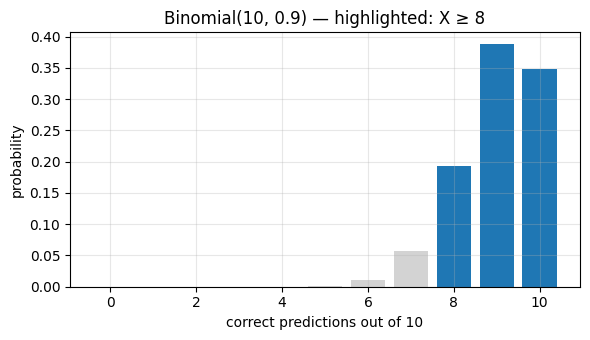

In [8]:
n, p = 10, 0.9
manual = sum(math.comb(n, k) * p**k * (1 - p)**(n - k) for k in (8, 9, 10))
scipy_val = stats.binom.sf(7, n, p)          # P(X > 7) = P(X >= 8)
print(f"P(X>=8) manual = {manual:.4f}, scipy = {scipy_val:.4f}")
print(f"E[X] = {n*p}, Var(X) = {n*p*(1-p):.1f}")
assert np.isclose(manual, scipy_val) and np.isclose(manual, 0.9298, atol=1e-4)

k = np.arange(0, n + 1)
plt.bar(k, stats.binom.pmf(k, n, p), color=["C0" if i >= 8 else "lightgray" for i in k])
plt.xlabel("correct predictions out of 10"); plt.ylabel("probability")
plt.title("Binomial(10, 0.9) — highlighted: X ≥ 8"); plt.tight_layout(); plt.show()

**ML connection.** The binomial model describes the number of correct predictions on a test set, which is the basis for confidence intervals on accuracy.

### Problem 2.4 — Naive Bayes classification
**Problem.** Using the data of Problem 2.1, an email contains both "free" and "win". Assume $P(\text{win}\mid\text{spam}) = 0.5$ and $P(\text{win}\mid\text{not spam}) = 0.05$, and that words are conditionally independent given the class. Classify the email.

**Solution.** From 2.1: $P(\text{spam}) = 0.4,\ P(\text{ham}) = 0.6,\ P(\text{free}\mid\text{spam}) = 0.75,\ P(\text{free}\mid\text{ham}) = 20/120 = 1/6$.

$$\text{score(spam)} = 0.4 \times 0.75 \times 0.5 = 0.15$$
$$\text{score(ham)} = 0.6 \times \tfrac{1}{6} \times 0.05 = 0.005$$

$$P(\text{spam}\mid\text{free, win}) = \frac{0.15}{0.15 + 0.005} \approx 0.968 \;\Rightarrow\; \textbf{spam}$$

In [9]:
prior = {"spam": 0.4, "ham": 0.6}
p_free = {"spam": 0.75, "ham": 20 / 120}
p_win = {"spam": 0.5, "ham": 0.05}
score = {c: prior[c] * p_free[c] * p_win[c] for c in prior}
posterior_spam = score["spam"] / sum(score.values())
print(score, f"-> P(spam | free, win) = {posterior_spam:.4f}")
assert np.isclose(score["spam"], 0.15) and np.isclose(score["ham"], 0.005) and posterior_spam > 0.96

{'spam': 0.15000000000000002, 'ham': 0.005} -> P(spam | free, win) = 0.9677


**ML connection.** This is exactly how a Naive Bayes classifier (`sklearn.naive_bayes`) works: multiply the class prior by per-feature likelihoods, then normalise. "Naive" refers to the conditional-independence assumption.

---
# Section 3 — Linear Algebra

### Problem 3.1 — Dot product, norm and cosine similarity
**Problem.** For $\mathbf u = (1,2,3)$ and $\mathbf v = (4,5,6)$ find $\mathbf u\cdot\mathbf v$, $\|\mathbf u\|$, $\|\mathbf v\|$, the cosine similarity and the angle between them.

**Solution.**

$$\mathbf u\cdot\mathbf v = 1(4)+2(5)+3(6) = 32$$
$$\|\mathbf u\| = \sqrt{1+4+9} = \sqrt{14} \approx 3.742, \qquad \|\mathbf v\| = \sqrt{16+25+36} = \sqrt{77} \approx 8.775$$
$$\cos\theta = \frac{\mathbf u\cdot\mathbf v}{\|\mathbf u\|\,\|\mathbf v\|} = \frac{32}{\sqrt{1078}} \approx 0.9746, \qquad \theta = \arccos(0.9746) \approx 12.9^\circ$$

The vectors point in almost the same direction.

In [10]:
u, v = np.array([1, 2, 3]), np.array([4, 5, 6])
dot = u @ v
norm_u, norm_v = np.linalg.norm(u), np.linalg.norm(v)
cos = dot / (norm_u * norm_v)
angle = np.degrees(np.arccos(cos))
print(f"dot = {dot}, |u| = {norm_u:.3f}, |v| = {norm_v:.3f}, cos = {cos:.4f}, angle = {angle:.2f}°")
assert dot == 32 and np.isclose(cos, 32 / np.sqrt(1078))

dot = 32, |u| = 3.742, |v| = 8.775, cos = 0.9746, angle = 12.93°


**ML connection.** Cosine similarity compares word/sentence embeddings, and is the core of search and retrieval (RAG) in Week 4.

### Problem 3.2 — One neural-network layer as matrix algebra
**Problem.** A layer has weights $W = \begin{pmatrix}1&2\\0&-1\\3&1\end{pmatrix}$, bias $\mathbf b = (1, 0, -2)$ and input $\mathbf x = (2, 1)$. Compute $\mathbf z = W\mathbf x + \mathbf b$ and the ReLU output. State the shapes and the number of parameters.

**Solution.**

$$W\mathbf x = \begin{pmatrix}1(2)+2(1)\\0(2)-1(1)\\3(2)+1(1)\end{pmatrix} = \begin{pmatrix}4\\-1\\7\end{pmatrix}, \qquad \mathbf z = \begin{pmatrix}4+1\\-1+0\\7-2\end{pmatrix} = \begin{pmatrix}5\\-1\\5\end{pmatrix}$$

$$\text{ReLU}(\mathbf z) = \max(0,\mathbf z) = (5,\ 0,\ 5)$$

Shapes: $(3\times2)(2\times1) = (3\times1)$. Parameters: $3\times2 + 3 = 9$.

In [11]:
W = np.array([[1, 2], [0, -1], [3, 1]]); b = np.array([1, 0, -2]); x = np.array([2, 1])
z = W @ x + b
a = np.maximum(0, z)
print("Wx =", W @ x, "| z =", z, "| ReLU(z) =", a)
print("shapes:", W.shape, x.shape, "->", z.shape, "| parameters:", W.size + b.size)
assert np.array_equal(z, [5, -1, 5]) and np.array_equal(a, [5, 0, 5])

Wx = [ 4 -1  7] | z = [ 5 -1  5] | ReLU(z) = [5 0 5]
shapes: (3, 2) (2,) -> (3,) | parameters: 9


**ML connection.** Every dense layer in PyTorch/Keras (Weeks 2–3) computes exactly $\text{activation}(W\mathbf x+\mathbf b)$; shapes must match for the matrix product to be defined.

### Problem 3.3 — Normal equation for linear regression
**Problem.** Fit $\hat y = \theta_0 + \theta_1 x$ to the points $(1,2),(2,3),(3,5)$ using $\boldsymbol\theta = (X^TX)^{-1}X^T\mathbf y$.

**Solution.**

$$X = \begin{pmatrix}1&1\\1&2\\1&3\end{pmatrix},\quad \mathbf y = \begin{pmatrix}2\\3\\5\end{pmatrix},\quad X^TX = \begin{pmatrix}3&6\\6&14\end{pmatrix},\quad X^T\mathbf y = \begin{pmatrix}10\\23\end{pmatrix}$$

$\det(X^TX) = 3(14) - 6(6) = 6 \neq 0$, so the inverse exists:

$$(X^TX)^{-1} = \frac16\begin{pmatrix}14&-6\\-6&3\end{pmatrix}, \qquad \boldsymbol\theta = \frac16\begin{pmatrix}14(10)-6(23)\\-6(10)+3(23)\end{pmatrix} = \frac16\begin{pmatrix}2\\9\end{pmatrix} = \begin{pmatrix}1/3\\3/2\end{pmatrix}$$

The fitted line is $\hat y = 0.333 + 1.5x$. Residuals are $(0.167,\ -0.333,\ 0.167)$, which sum to 0, and $SSE = 1/6 \approx 0.167$.

X^T X =
 [[ 3.  6.]
 [ 6. 14.]] 
X^T y = [10. 23.] 
det(X^T X) = 6.0
theta = [0.3333 1.5   ] | residuals = [ 0.1667 -0.3333  0.1667] | SSE = 0.1667


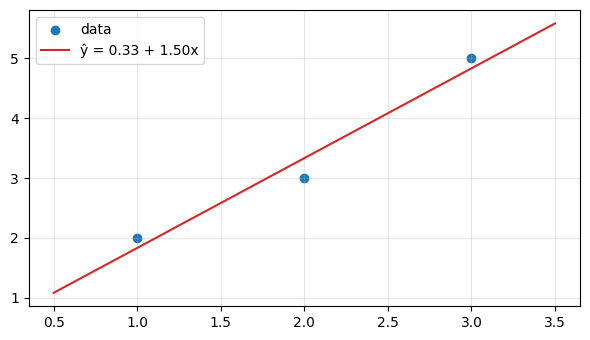

In [12]:
X = np.array([[1, 1], [1, 2], [1, 3]], dtype=float); y = np.array([2, 3, 5], dtype=float)
XtX, Xty = X.T @ X, X.T @ y
print("X^T X =\n", XtX, "\nX^T y =", Xty, "\ndet(X^T X) =", round(np.linalg.det(XtX), 4))

theta = np.linalg.inv(XtX) @ Xty
y_hat = X @ theta; resid = y - y_hat
print("theta =", theta, "| residuals =", resid, "| SSE =", round((resid**2).sum(), 4))

assert np.allclose(theta, [1/3, 3/2])
assert np.allclose(theta, np.linalg.solve(XtX, Xty))
assert np.allclose(theta, np.linalg.lstsq(X, y, rcond=None)[0])

plt.scatter(X[:, 1], y, label="data"); xs = np.linspace(0.5, 3.5, 10)
plt.plot(xs, theta[0] + theta[1] * xs, color="C3", label=f"ŷ = {theta[0]:.2f} + {theta[1]:.2f}x")
plt.legend(); plt.tight_layout(); plt.show()

**ML connection.** `LinearRegression` in scikit-learn (Task 1.4) solves this same least-squares problem. In practice `solve`/`lstsq` is preferred over an explicit inverse for numerical stability.

### Problem 3.4 — Eigenvalues, eigenvectors and PCA
**Problem.** A covariance matrix is $C = \begin{pmatrix}3&1\\1&3\end{pmatrix}$. Find its eigenvalues and eigenvectors and the share of variance along the first principal component.

**Solution.** Solve $\det(C-\lambda I) = 0$:

$$(3-\lambda)^2 - 1 = 0 \;\Rightarrow\; \lambda^2 - 6\lambda + 8 = 0 \;\Rightarrow\; \lambda_1 = 4,\ \lambda_2 = 2$$

- $\lambda_1 = 4$: $(C-4I)\mathbf v = \begin{pmatrix}-1&1\\1&-1\end{pmatrix}\mathbf v = 0 \Rightarrow \mathbf v_1 = \tfrac{1}{\sqrt2}(1,1)$
- $\lambda_2 = 2$: $(C-2I)\mathbf v = \begin{pmatrix}1&1\\1&1\end{pmatrix}\mathbf v = 0 \Rightarrow \mathbf v_2 = \tfrac{1}{\sqrt2}(1,-1)$

Checks: $\lambda_1+\lambda_2 = 6 = \text{trace}(C)$ and $\lambda_1\lambda_2 = 8 = \det(C)$.

Variance explained by PC1 $= \dfrac{4}{4+2} = 66.7\%$.

eigenvalues = [4. 2.] | explained variance ratio = [0.6667 0.3333]
eigenvectors (columns) =
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]


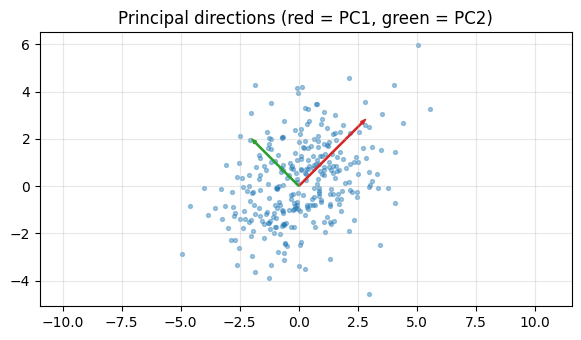

In [13]:
C = np.array([[3.0, 1.0], [1.0, 3.0]])
vals, vecs = np.linalg.eigh(C)                     # ascending order
vals, vecs = vals[::-1], vecs[:, ::-1]             # largest first
print("eigenvalues =", vals, "| explained variance ratio =", vals / vals.sum())
print("eigenvectors (columns) =\n", vecs)
assert np.allclose(vals, [4, 2]) and np.isclose(vals.sum(), np.trace(C)) and np.isclose(vals.prod(), np.linalg.det(C))

# Visual: sample data with this covariance and the principal directions
rng = np.random.default_rng(0)
pts = rng.multivariate_normal([0, 0], C, size=300)
plt.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.4)
for lam, vec, col in zip(vals, vecs.T, ["C3", "C2"]):
    plt.arrow(0, 0, *(vec * np.sqrt(lam) * 2), color=col, width=0.05, length_includes_head=True)
plt.axis("equal"); plt.title("Principal directions (red = PC1, green = PC2)"); plt.tight_layout(); plt.show()

**ML connection.** PCA keeps the eigenvectors of the covariance matrix with the largest eigenvalues to reduce dimensions while preserving variance.

---
# Section 4 — Basic Calculus

### Problem 4.1 — Derivative of the mean squared error
**Problem.** For the model $\hat y = wx$ and loss $L(w) = \dfrac1n\sum_{i}(y_i - wx_i)^2$, derive $\dfrac{dL}{dw}$. With $x = (1,2,3)$, $y = (2,4,6)$ and $w = 1$, compute $L$, the gradient, and one update with learning rate $\eta = 0.1$.

**Solution.** By the chain rule, $\dfrac{d}{dw}(y_i - wx_i)^2 = 2(y_i - wx_i)(-x_i)$, so

$$\frac{dL}{dw} = -\frac{2}{n}\sum_i x_i\,(y_i - wx_i)$$

At $w=1$: residuals $y - wx = (1,2,3)$ and $\sum x_i(y_i-wx_i) = 1+4+9 = 14$.

$$L(1) = \frac{1+4+9}{3} = 4.667, \qquad \frac{dL}{dw} = -\frac{2}{3}(14) = -9.333$$

Update: $w \leftarrow w - \eta\,\dfrac{dL}{dw} = 1 - 0.1(-9.333) = 1.933$ (it moves toward the true value $w = 2$).

In [14]:
x = np.array([1.0, 2.0, 3.0]); y = np.array([2.0, 4.0, 6.0])
L = lambda w: np.mean((y - w * x) ** 2)
grad = lambda w: -2 * np.mean(x * (y - w * x))

w = 1.0
h = 1e-6
numeric = (L(w + h) - L(w - h)) / (2 * h)          # finite-difference check
print(f"L(1) = {L(1):.4f}, analytic grad = {grad(1):.4f}, numeric grad = {numeric:.4f}")
print(f"after one step (lr=0.1): w = {w - 0.1 * grad(w):.4f}, L = {L(w - 0.1 * grad(w)):.4f}")
assert np.isclose(grad(1), -28 / 3) and np.isclose(grad(1), numeric, atol=1e-4) and np.isclose(grad(2), 0)

L(1) = 4.6667, analytic grad = -9.3333, numeric grad = -9.3333
after one step (lr=0.1): w = 1.9333, L = 0.0207


**ML connection.** This is the gradient that trains linear regression by gradient descent. At the optimum ($w=2$) the gradient is 0.

### Problem 4.2 — Partial derivatives, gradient and saddle points
**Problem.** Let $f(x,y) = x^2 + 3xy + y^2$. Find $\nabla f$, evaluate it at $(1,2)$, find the stationary point and classify it.

**Solution.**

$$\frac{\partial f}{\partial x} = 2x + 3y, \qquad \frac{\partial f}{\partial y} = 3x + 2y \;\Rightarrow\; \nabla f(1,2) = (2+6,\ 3+4) = (8,\ 7)$$

The direction of steepest *descent* at $(1,2)$ is $-\nabla f = (-8,-7)$.

Stationary point: $2x+3y = 0$ and $3x+2y = 0$ give $x=y=0$.

Hessian: $H = \begin{pmatrix}2&3\\3&2\end{pmatrix}$, with eigenvalues from $(2-\lambda)^2 - 9 = 0 \Rightarrow \lambda = 5,\ -1$.
One positive and one negative eigenvalue means $(0,0)$ is a **saddle point**, not a minimum.

In [15]:
f = lambda p: p[0]**2 + 3 * p[0] * p[1] + p[1]**2
grad_f = lambda p: np.array([2 * p[0] + 3 * p[1], 3 * p[0] + 2 * p[1]])

def numeric_grad(fn, p, h=1e-6):
    p = np.array(p, float); g = np.zeros_like(p)
    for i in range(len(p)):
        e = np.zeros_like(p); e[i] = h
        g[i] = (fn(p + e) - fn(p - e)) / (2 * h)
    return g

print("grad at (1,2):", grad_f([1, 2]), "| numeric:", numeric_grad(f, [1, 2]))
H = np.array([[2, 3], [3, 2]])
print("Hessian eigenvalues:", np.linalg.eigvalsh(H), "-> saddle point")
assert np.allclose(grad_f([1, 2]), [8, 7]) and np.allclose(numeric_grad(f, [1, 2]), [8, 7], atol=1e-4)
assert np.allclose(np.linalg.eigvalsh(H), [-1, 5])

grad at (1,2): [8 7] | numeric: [8. 7.]
Hessian eigenvalues: [-1.  5.] -> saddle point


**ML connection.** Gradient descent follows $-\nabla f$. High-dimensional loss surfaces have many saddle points, where the gradient is zero but the point is not a minimum.

### Problem 4.3 — Chain rule: sigmoid and binary cross-entropy
**Problem.** For $a = \sigma(z) = \dfrac{1}{1+e^{-z}}$ show $\sigma'(z) = \sigma(z)(1-\sigma(z))$. For the loss $L = -[\,y\ln a + (1-y)\ln(1-a)\,]$ show $\dfrac{dL}{dz} = a - y$, then evaluate at $z = 2,\ y = 1$.

**Solution.**

$\sigma(z) = (1+e^{-z})^{-1}$, so $\sigma'(z) = e^{-z}(1+e^{-z})^{-2} = \dfrac{1}{1+e^{-z}}\cdot\dfrac{e^{-z}}{1+e^{-z}} = \sigma(z)\,(1-\sigma(z))$. Its maximum is $\sigma'(0) = 0.25$.

Chain rule: $\dfrac{dL}{dz} = \dfrac{dL}{da}\cdot\dfrac{da}{dz}$ with $\dfrac{dL}{da} = -\dfrac{y}{a} + \dfrac{1-y}{1-a}$ and $\dfrac{da}{dz} = a(1-a)$:

$$\frac{dL}{dz} = \Big(-\frac{y}{a} + \frac{1-y}{1-a}\Big)a(1-a) = -y(1-a) + (1-y)a = a - y$$

At $z=2$: $a = \sigma(2) \approx 0.8808$, so with $y=1$: $\dfrac{dL}{dz} = 0.8808 - 1 = -0.1192$.

In [16]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
bce = lambda z, y: -(y * np.log(sigmoid(z)) + (1 - y) * np.log(1 - sigmoid(z)))

z, y, h = 2.0, 1.0, 1e-6
analytic = sigmoid(z) - y
numeric = (bce(z + h, y) - bce(z - h, y)) / (2 * h)
print(f"sigmoid(2) = {sigmoid(2):.4f}, dL/dz analytic = {analytic:.4f}, numeric = {numeric:.4f}")
print("sigmoid'(0) =", sigmoid(0) * (1 - sigmoid(0)))
assert np.isclose(analytic, numeric, atol=1e-6) and np.isclose(analytic, -0.1192, atol=1e-4)

sigmoid(2) = 0.8808, dL/dz analytic = -0.1192, numeric = -0.1192
sigmoid'(0) = 0.25


**ML connection.** The clean result $a - y$ is why logistic regression and neural-network classifiers train so smoothly with cross-entropy, and it is what backpropagation uses in the final layer (Week 2).

### Problem 4.4 — Gradient descent by hand and in code
**Problem.** Minimise $f(w) = (w-3)^2 + 2$ starting from $w_0 = 0$ with learning rate $\eta = 0.1$. Perform 3 steps by hand, find a closed form, and explain what happens for other learning rates.

**Solution.** $f'(w) = 2(w-3)$ and the update is $w_{k+1} = w_k - \eta f'(w_k)$.

| step | $w_k$ | $f'(w_k)$ | $w_{k+1}$ |
|---|---|---|---|
| 0 | 0 | $-6$ | $0 - 0.1(-6) = 0.6$ |
| 1 | 0.6 | $-4.8$ | $0.6 + 0.48 = 1.08$ |
| 2 | 1.08 | $-3.84$ | $1.08 + 0.384 = 1.464$ |

Rewriting the update: $w_{k+1} - 3 = (1-2\eta)(w_k - 3)$, so $w_k = 3 - 3(1-2\eta)^k$.
With $\eta = 0.1$ the factor is $0.8$ (smooth convergence to 3). The iteration converges when $|1-2\eta| < 1$, i.e. $0 < \eta < 1$:
- $\eta = 0.01$: factor $0.98$ — converges very slowly.
- $\eta = 0.9$: factor $-0.8$ — oscillates but converges.
- $\eta = 1.1$: factor $-1.2$ — **diverges**.

first steps (lr=0.1): [0.    0.6   1.08  1.464]


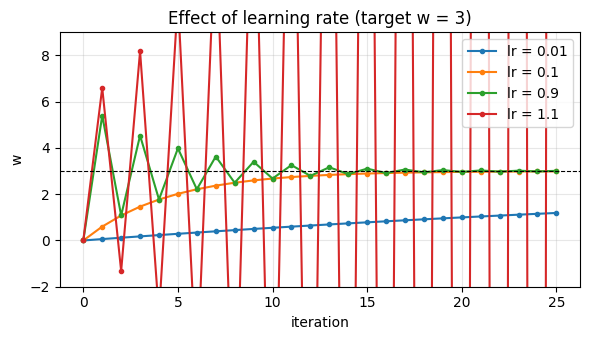

In [17]:
fprime = lambda w: 2 * (w - 3)

def descend(lr, steps, w0=0.0):
    path = [w0]
    for _ in range(steps):
        path.append(path[-1] - lr * fprime(path[-1]))
    return np.array(path)

path = descend(0.1, 3)
print("first steps (lr=0.1):", path)
assert np.allclose(path, [0, 0.6, 1.08, 1.464])
assert np.allclose(path, 3 - 3 * 0.8 ** np.arange(4))          # closed form

for lr in (0.01, 0.1, 0.9, 1.1):
    plt.plot(descend(lr, 25), marker="o", ms=3, label=f"lr = {lr}")
plt.axhline(3, color="k", ls="--", lw=0.8)
plt.ylim(-2, 9); plt.xlabel("iteration"); plt.ylabel("w")
plt.title("Effect of learning rate (target w = 3)"); plt.legend(); plt.tight_layout(); plt.show()

**ML connection.** This is the core training loop of every model in Weeks 2–4. The learning rate is the most important hyper-parameter: too small is slow, too large diverges.

---
# Summary of results
| # | Topic | Result |
|---|---|---|
| 1.1 | Mean / median / mode; σ, s | 15 / 15 / 15; σ² = 6.8, s² = 7.556 |
| 1.2 | Normal $N(70,10)$ | P(X<85) = 0.9332; P(60<X<80) = 0.6827; top-10% cut-off = 82.82 |
| 1.3 | Correlation & line | r = 0.9922; ŷ = 44.9 + 5.7x; ŷ(6) = 79.1 |
| 1.4 | 95% CI of mean | (47.87, 56.13) |
| 2.1 | Conditional probability | P(spam \| free) = 0.75; not independent |
| 2.2 | Bayes (fraud) | P(fraud \| flagged) = 0.161 |
| 2.3 | Binomial(10, 0.9) | P(X ≥ 8) = 0.9298; E = 9; Var = 0.9 |
| 2.4 | Naive Bayes | P(spam \| free, win) = 0.968 |
| 3.1 | Cosine similarity | 0.9746 (12.9°) |
| 3.2 | Dense layer | z = (5, −1, 5); ReLU → (5, 0, 5); 9 parameters |
| 3.3 | Normal equation | θ = (1/3, 3/2); SSE = 1/6 |
| 3.4 | Eigen / PCA | λ = 4, 2; PC1 explains 66.7% |
| 4.1 | MSE gradient | dL/dw = −9.333; w → 1.933 |
| 4.2 | Gradient & Hessian | ∇f(1,2) = (8, 7); saddle at (0,0) |
| 4.3 | Sigmoid + BCE | dL/dz = a − y = −0.1192 |
| 4.4 | Gradient descent | 0 → 0.6 → 1.08 → 1.464; diverges if η > 1 |

*Every hand-derived answer above is checked by an `assert` in the notebook: if you change a number and re-run, the cell tells you whether your hand calculation still matches.*